# **Construcción de un dataset de imagenes para Agrotrace**

El contexto principal que logra explicar la necesidad de este notebook son los datos de entrenamiento para nuestro modelo de clasificación. Al querer entrenar un modelo de tal magnitud para clasificar imagenes de frutas (proporcionadas por los agricultores) en tres estados, necesitamos un dataset en el cual nuestro modelo se pueda basar para aprender patrones que lo lleven a distinguir entre una fruta fresca, de calidad regular y una fruta podrida.

El problema ronda en que hay muy pocos datasets públicos que logran acoplarse a nuestro dominio ya que, por lo general, los datasets públicos con imagenes de frutas solo dividen las imagenes en dos clases `fresh` y `rotten` dejando por fuera una clase intermedia (necesaria en nuestro caso). Sin embargo, los datasets públicos que se acoplan al dominio en el que se basa agrotrace tienen ciertos problemas en cuanto a las imagenes y su calidad, problemas que pueden afectar la calidad del modelo a entrenar y su futuro performance en el microservicio de clasificación.

En este notebook exploramos diferentes datasets públicos con el fin de crear un dataset propio, unificado y limpio, que se adapte a las tres clases que maneja agrotrace (fresca, regular y podrida). Para lograrlo, analizamos la calidad de las imagenes de cada fuente (resolución, fondos, iluminación, duplicados e imagenes mal etiquetadas), filtramos aquellas que no aportan valor al entrenamiento, reasignamos las etiquetas de cada fuente a nuestras tres clases y balanceamos la cantidad de imagenes por clase. Por último, subimos el dataset a `Hugging Face` para su libre uso en otros proyectos.

Montamos google drive en la sesión de colab para trabajar sobre este e ir sincronizando nuestro progreso.

In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


Guardamos todo en Drive para no repetir descargas ni limpiezas entre sesiones.

In [2]:
from pathlib import Path

DRIVE_DIR = Path('/content/drive/MyDrive')
FRUQ_DIR = DRIVE_DIR / 'fruq'

## **1. FruQ-multi**

`FruitQ-multi dataset` es un dataset que contiene 11 variedades de imagenes de frutas. Estas imagenes fueron creadas a partir de videos de youtube (tipo time-lapse) en los que se observaban los procesos de descomposición de las frutas pasando desde un estado fresco hasta podrido.

* **Ventaja:** Se ajusta a nuestro dominio puesto que el dataset separa las imagenes entre `fresh`,`mild` y `rotten`.
* **Desventaja:** Al ser frames extraidos desde un video de youtube, hay fotogramas identicos a los demás. Si entrenamos un modelo con estos datos corremos el riesgo de terminar con datos identicos en los sets de train y testing, haciendo que el modelo reporte un accuracy muy alto sin realmente haber aprendido patrones reales para clasificar las fotos.

In [3]:
# Descargamos el zip al disco local de Colab y solo descomprimimos en Drive, así no ocupamos 4,3 GB extra en Drive. Si ya está descomprimido, no se repite.
if not (FRUQ_DIR / 'FruQ-multi').exists():
    !wget -O /content/FruQ-DB.zip "https://zenodo.org/records/7224690/files/FruQ-multi.zip?download=1"
    !unzip -q /content/FruQ-DB.zip -d "{FRUQ_DIR}"
    !rm /content/FruQ-DB.zip
else:
    print(f'FruQ-multi ya está en {FRUQ_DIR}')

--2026-10-22 03:55:14--  https://zenodo.org/records/7224690/files/FruQ-multi.zip?download=1
Resolving zenodo.org (zenodo.org)... 137.138.121.78, 188.185.40.132, 188.185.51.60, ...
Connecting to zenodo.org (zenodo.org)|137.138.121.78|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 4661201538 (4.3G) [application/octet-stream]
Saving to: ‘/content/FruQ-DB.zip’

/content/FruQ-DB.zi 100%[===================>]   4.34G  3.67MB/s    in 19m 53s 

2026-10-22 04:15:08 (3.73 MB/s) - ‘/content/FruQ-DB.zip’ saved [4661201538/4661201538]



Inspeccionemos la estructura de la carpeta que contiene al dataset

In [4]:
!ls "{FRUQ_DIR}/FruQ-multi/"

BananaDB   GrapeQ  PapayaQ  PearQ    StrawberryQ  WatermeloQ
CucumberQ  KakiQ   PeachQ   PepperQ  tomatoQ


Como podemos ver, internamente tenemos carpetas con el nombre de cada fruta. Pasemos a ver como se estructuran internamente las carpetas.

In [5]:
!ls "{FRUQ_DIR}/FruQ-multi/BananaDB"

Good  mild  Rotten


Teniendo claro como se estructuran internamente las subcarpetas, pasemos a analizar las imagenes.

In [ ]:
import os
import matplotlib.image as mpimg
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 15))

# En la sección 4 renombramos Good a Fresh, así que usamos la que exista.
banana_dir = FRUQ_DIR / 'FruQ-multi' / 'BananaDB'
folder = banana_dir / 'Good' if (banana_dir / 'Good').exists() else banana_dir / 'Fresh'
images = os.listdir(folder)

for i, imagename in enumerate(images[:20]):
    plt.subplot(5, 5, i + 1)
    img = mpimg.imread(folder / imagename)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(img)

Como podemos evidenciar, estamos mostrando 20 imagenes de la clase Banana (en un buen estado) pero a nivel visual hay fotogramas que se ven idénticos, por lo tanto necesitamos analizar la similitud entre imagenes para tomar desiciones sobre estos datos.

### **1.1 Detección de duplicados**

Para cuantificar el problema calculamos dos hashes por imagen:

* **SHA-256:** detecta archivos idénticos byte a byte (duplicados exactos).
* **pHash (perceptual hash):** resume la estructura visual de la imagen en 64 bits. Dos fotogramas casi iguales tienen hashes con una distancia de Hamming pequeña, aunque sus bytes difieran (compresión, ligeros cambios de luz, etc.).

Como los fotogramas de cada fruta provienen de su propio video, solo comparamos imágenes **dentro de la misma fruta**. Esto reduce drásticamente el número de pares a evaluar y evita falsos positivos entre frutas distintas.

Además del número de duplicados, nos interesa un caso especialmente dañino: **pares casi idénticos con etiquetas distintas** (por ejemplo, el mismo fotograma en `Good` y en `mild`). Estos pares indican fronteras ambiguas entre clases y son candidatos a revisión o eliminación.

In [8]:
!pip install -q imagehash

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 5.7 MB/s eta 0:00:00a 0:00:01


In [9]:
import hashlib
from collections import defaultdict
from itertools import combinations
from pathlib import Path

import imagehash
import pandas as pd
from PIL import Image, UnidentifiedImageError
from tqdm.auto import tqdm

In [5]:
# Configuración
DATASET_DIR = FRUQ_DIR / 'FruQ-multi'
REPORT_PATH = FRUQ_DIR / 'fruq_duplicate_report.csv'

IMAGE_EXTENSIONS = {
    '.jpg', '.jpeg', '.png', '.webp', '.bmp', '.tiff'
}

# Un hash pHash estándar contiene 64 bits.
# Menor distancia = mayor similitud.
PHASH_THRESHOLD = 2

REPORT_COLUMNS = [
    'fruit',
    'image_1', 'image_2',
    'label_1', 'label_2',
    'type', 'phash_distance', 'same_label',
]

In [10]:
def sha256_file(path: Path) -> str:
    """Calcula el SHA-256 de un archivo."""
    digest = hashlib.sha256()

    with path.open('rb') as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b''):
            digest.update(chunk)

    return digest.hexdigest()

In [11]:
def load_images(root: Path) -> list[dict]:
    """Obtiene la ruta, la fruta, la etiqueta, el hash exacto y el pHash."""
    paths = [
        path for path in sorted(root.rglob('*'))
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
    ]
    records = []

    for path in tqdm(paths, desc='Calculando hashes'):
        try:
            exact_hash = sha256_file(path)

            with Image.open(path) as image:
                perceptual_hash = imagehash.phash(image.convert('RGB'))

            # Estructura de FruQ-multi: <Fruta>/<Estado>/<imagen>.
            # Normalizamos el estado porque las carpetas mezclan
            # mayúsculas y minúsculas (Good, mild, Rotten).
            fruit, label = path.relative_to(root).parts[:2]

            records.append({
                'path': str(path),
                'fruit': fruit,
                'label': label.lower(),
                'sha256': exact_hash,
                'phash': perceptual_hash,
            })

        except (OSError, ValueError, UnidentifiedImageError) as error:
            print(f'No se pudo procesar {path}: {error}')

    return records

In [12]:
def detect_duplicates(records: list[dict]) -> list[dict]:
    """Detecta duplicados exactos y visualmente similares dentro de cada fruta."""
    by_fruit = defaultdict(list)
    for record in records:
        by_fruit[record['fruit']].append(record)

    matches = []

    for fruit, fruit_records in tqdm(by_fruit.items(), desc='Comparando pares'):
        for first, second in combinations(fruit_records, 2):
            # Primero comprobamos si los archivos son idénticos.
            if first['sha256'] == second['sha256']:
                match_type = 'exact'
                distance = 0

            else:
                distance = first['phash'] - second['phash']

                if distance > PHASH_THRESHOLD:
                    continue

                match_type = 'visual'

            matches.append({
                'fruit': fruit,
                'image_1': first['path'],
                'image_2': second['path'],
                'label_1': first['label'],
                'label_2': second['label'],
                'type': match_type,
                'phash_distance': distance,
                'same_label': first['label'] == second['label'],
            })

    return matches

In [13]:
records = load_images(DATASET_DIR)
matches = detect_duplicates(records)

images_df = pd.DataFrame(records).drop(columns='phash')
matches_df = pd.DataFrame(matches, columns=REPORT_COLUMNS)
matches_df.to_csv(REPORT_PATH, index=False)

print(f"Imágenes procesadas: {len(images_df)}")
print(f"Pares idénticos: {(matches_df['type'] == 'exact').sum()}")
print(f"Pares visualmente similares: {(matches_df['type'] == 'visual').sum()}")
print(f"Pares con etiquetas diferentes: {(~matches_df['same_label']).sum()}")
print(f"Informe generado: {REPORT_PATH}")

Calculando hashes:   0%|          | 0/9370 [00:00<?, ?it/s]

Comparando pares:   0%|          | 0/11 [00:00<?, ?it/s]

Imágenes procesadas: 9370
Pares idénticos: 0
Pares visualmente similares: 728149
Pares con etiquetas diferentes: 39739
Informe generado: /content/drive/MyDrive/fruq/fruq_duplicate_report.csv


Resumimos los resultados por fruta: cuántas imágenes tiene, cuántos pares exactos y visuales encontramos, cuántos pares tienen etiquetas diferentes y qué porcentaje de las imágenes tiene al menos un duplicado.

In [14]:
# Imágenes que aparecen en al menos un par de duplicados.
duplicated_paths = pd.unique(matches_df[['image_1', 'image_2']].values.ravel())
images_df['has_duplicate'] = images_df['path'].isin(duplicated_paths)

summary = pd.concat([
    images_df.groupby('fruit').size().rename('images'),
    matches_df.groupby(['fruit', 'type']).size().unstack(fill_value=0),
    matches_df[~matches_df['same_label']].groupby('fruit').size().rename('label_conflicts'),
    images_df.groupby('fruit')['has_duplicate'].mean().mul(100).round(1).rename('% with_duplicate'),
], axis=1).fillna(0)

display(summary.sort_values('% with_duplicate', ascending=False))

# Entre qué clases se presentan los conflictos de etiqueta.
display(pd.crosstab(
    matches_df.loc[~matches_df['same_label'], 'label_1'],
    matches_df.loc[~matches_df['same_label'], 'label_2'],
))

,images,visual,label_conflicts,% with_duplicate
fruit,,,,
BananaDB,612,45187,1210.0,100.0
CucumberQ,711,73953,27612.0,100.0
GrapeQ,709,35016,426.0,100.0
PapayaQ,793,82835,6126.0,100.0
PeachQ,1145,78026,0.0,100.0
StrawberryQ,216,4709,378.0,100.0
PepperQ,732,30851,0.0,100.0
WatermeloQ,254,5231,481.0,100.0
tomatoQ,1990,119321,811.0,100.0


label_2,mild,rotten
label_1,,
fresh,27612,0
good,7290,0
mild,0,4163
rotten,674,0


Veamos algunos de los pares con etiquetas diferentes para confirmar visualmente si se trata del mismo fotograma.

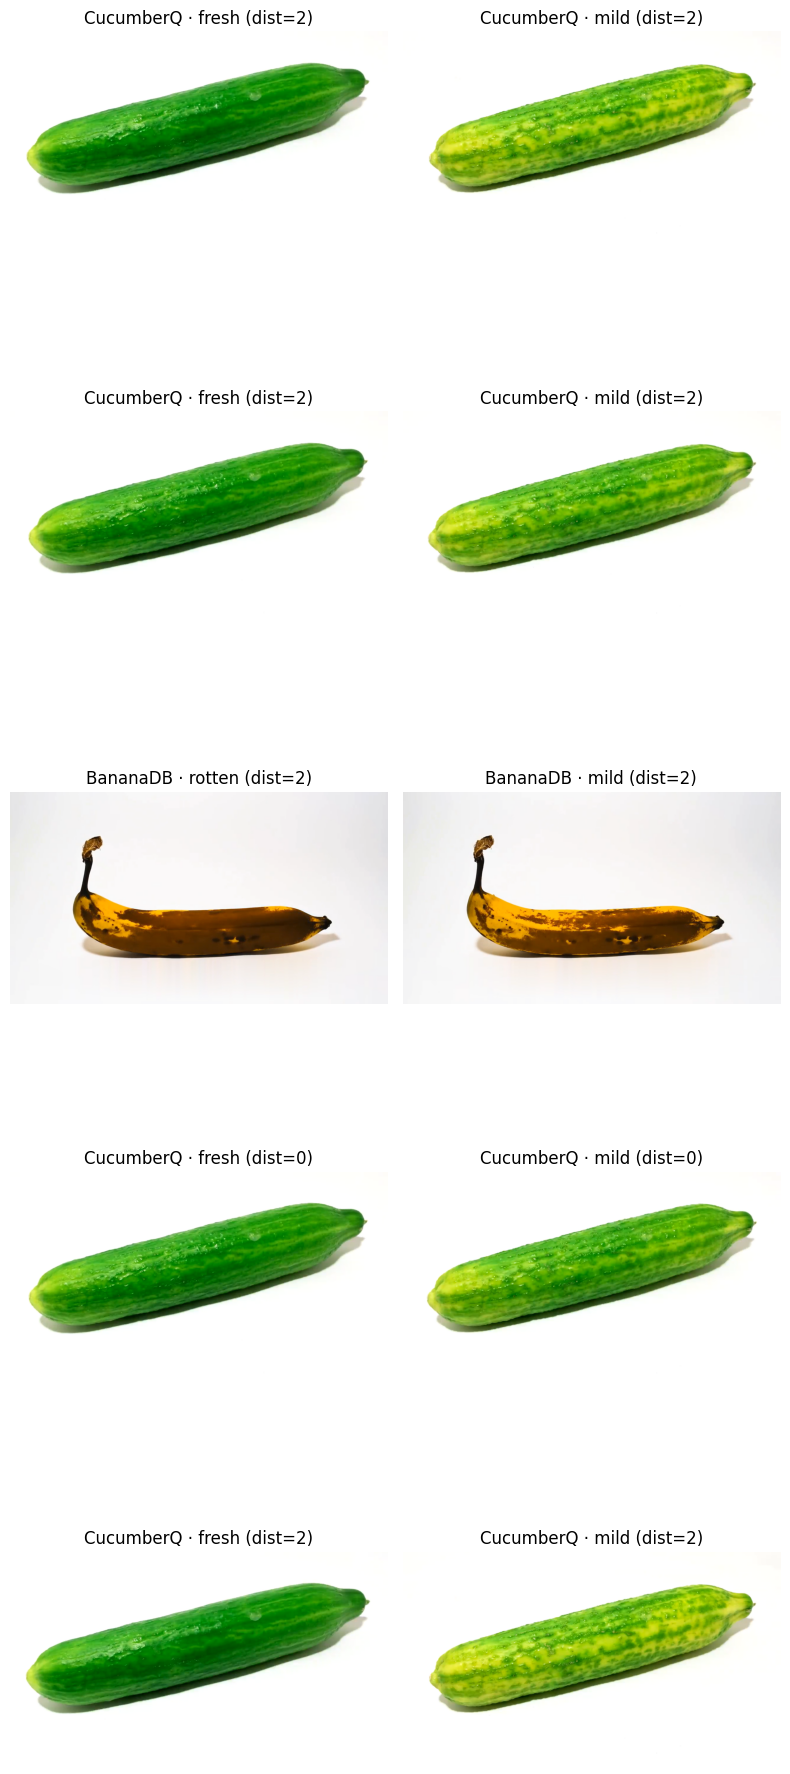

In [15]:
conflicts_df = matches_df[~matches_df['same_label']]

if conflicts_df.empty:
    print('No hay pares con etiquetas diferentes.')
else:
    sample = conflicts_df.sample(min(5, len(conflicts_df)), random_state=42)
    fig, axes = plt.subplots(len(sample), 2, figsize=(8, 4 * len(sample)), squeeze=False)

    for row, (_, match) in zip(axes, sample.iterrows()):
        pair = ((match['image_1'], match['label_1']), (match['image_2'], match['label_2']))

        for ax, (path, label) in zip(row, pair):
            with Image.open(path) as image:
                ax.imshow(image)
            ax.set_title(f"{match['fruit']} · {label} (dist={match['phash_distance']})")
            ax.axis('off')

    plt.tight_layout()
    plt.show()

### **1.2 Limpieza del dataset**

Los resultados anteriores confirman el problema descrito al inicio:

* **El 100% de las imágenes tiene al menos un casi-duplicado**, incluso con un umbral muy estricto (`PHASH_THRESHOLD = 2`). Como cada fruta proviene de uno o pocos videos con cámara fija, en la práctica no tenemos 9.370 muestras independientes sino unas pocas escenas repetidas.
* **Hay 39.739 pares con etiquetas distintas.** En un time-lapse los fotogramas en la frontera entre dos estados son, por definición, muy parecidos. Además, pHash trabaja en escala de grises y el deterioro de una fruta es principalmente un cambio de color, por lo que estos pares no son necesariamente errores de etiquetado, pero sí representan las fronteras más ambiguas entre clases.
* **Las etiquetas no son consistentes entre frutas:** algunas carpetas usan `Good` y otras `Fresh` para el mismo estado.

Para limpiar el dataset seguimos tres pasos:

1. Normalizar las etiquetas a las tres clases de Agrotrace.
2. Eliminar las imágenes que forman parte de pares con etiquetas distintas.
3. Evaluar si conviene deduplicar las imágenes dentro de cada fruta y estado.

#### **1.2.1 Normalización de etiquetas**

Unificamos `good` y `fresh` en una sola clase y recalculamos qué pares tienen etiquetas distintas con las etiquetas ya normalizadas.

In [16]:
LABEL_MAPPING = {
    'good': 'fresh',
    'fresh': 'fresh',
    'mild': 'mild',
    'rotten': 'rotten',
}

images_df['label'] = images_df['label'].map(LABEL_MAPPING)
matches_df['label_1'] = matches_df['label_1'].map(LABEL_MAPPING)
matches_df['label_2'] = matches_df['label_2'].map(LABEL_MAPPING)
matches_df['same_label'] = matches_df['label_1'] == matches_df['label_2']

display(images_df.groupby(['fruit', 'label']).size().unstack(fill_value=0))

label,fresh,mild,rotten
fruit,,,
BananaDB,179,96,337
CucumberQ,250,345,116
GrapeQ,227,194,288
KakiQ,545,226,340
PapayaQ,130,250,413
PeachQ,425,136,584
PearQ,504,493,100
PepperQ,48,24,660
StrawberryQ,0,119,97


#### **1.2.2 Eliminación de fronteras ambiguas**

Descartamos toda imagen que tenga un casi-duplicado con una etiqueta diferente. Así evitamos que el modelo reciba dos imágenes prácticamente iguales con clases distintas.

In [17]:
conflicts_df = matches_df[~matches_df['same_label']]
conflict_paths = set(conflicts_df[['image_1', 'image_2']].values.ravel())

images_df['is_conflict'] = images_df['path'].isin(conflict_paths)

print(f"Imágenes en conflicto: {images_df['is_conflict'].sum()}")
display(
    images_df.groupby('fruit')['is_conflict']
    .mean().mul(100).round(1)
    .rename('% in_conflict')
    .sort_values(ascending=False)
)

Imágenes en conflicto: 1374


,% in_conflict
fruit,
CucumberQ,60.6
BananaDB,31.9
WatermeloQ,31.9
PapayaQ,22.4
StrawberryQ,20.4
GrapeQ,19.3
KakiQ,11.2
tomatoQ,9.2
PeachQ,0.0


#### **1.2.3 Experimento de deduplicación**

Para cada combinación de fruta y estado recorremos las imágenes en orden y conservamos una imagen solo si su distancia pHash con **todas** las imágenes ya conservadas supera `MIN_DISTANCE`. El resultado es un conjunto de representantes visualmente distintos entre sí.

No usamos componentes conexas (agrupar todas las imágenes unidas por algún par similar) porque, con tantos pares, las cadenas de similitud terminan uniendo cada fruta en un único grupo gigante y perderíamos casi todo el dataset.

`MIN_DISTANCE` controla el balance entre diversidad y cantidad de datos: un valor mayor deja menos imágenes pero más diferentes entre sí. Como primer experimento probamos con un valor estricto (`MIN_DISTANCE = 8`).

In [18]:
MIN_DISTANCE = 8

phash_by_path = {record['path']: record['phash'] for record in records}

In [19]:
def deduplicate(paths: list[str], min_distance: int) -> list[str]:
    """Conserva solo las imágenes a más de `min_distance` de todas las ya conservadas."""
    kept_paths = []
    kept_hashes = []

    for path in sorted(paths):
        current_hash = phash_by_path[path]

        if all(current_hash - kept_hash > min_distance for kept_hash in kept_hashes):
            kept_paths.append(path)
            kept_hashes.append(current_hash)

    return kept_paths

In [20]:
candidates_df = images_df[~images_df['is_conflict']]
kept_paths = []

for _, group in tqdm(candidates_df.groupby(['fruit', 'label']), desc='Deduplicando'):
    kept_paths.extend(deduplicate(group['path'].tolist(), MIN_DISTANCE))

print(f"Imágenes candidatas: {len(candidates_df)}")
print(f"Imágenes conservadas: {len(kept_paths)} ({len(kept_paths) / len(images_df):.1%})")

Deduplicando:   0%|          | 0/32 [00:00<?, ?it/s]

Imágenes candidatas: 7996
Imágenes conservadas: 82 (0.9%)


Con `MIN_DISTANCE = 8` solo conservamos **82 imágenes (0,9%)**, entre 1 y 11 por fruta y estado. Este resultado no es un error: es la diversidad real de FruQ-multi. Como cada video se grabó con cámara fija, la misma fruta y el mismo fondo, el dataset tiene apenas unas 82 vistas estructuralmente distintas.

Además, este experimento muestra una limitación de pHash para nuestro dominio: **pHash trabaja en escala de grises y mide la estructura de la imagen, no el color**. Dentro de una misma clase, los fotogramas sí cambian con el tiempo (pardeamiento, manchas, pérdida de brillo), que es justamente la información que el modelo debe aprender, pero para pHash son la misma imagen.

Para comprobar si existe algún umbral que conserve una cantidad útil de imágenes, hacemos un barrido de `MIN_DISTANCE` y observamos cuántas imágenes se conservan con cada valor.

In [21]:
sweep = []

for min_distance in tqdm(range(0, 9), desc='Barrido de MIN_DISTANCE'):
    kept = []
    for _, group in candidates_df.groupby(['fruit', 'label']):
        kept.extend(deduplicate(group['path'].tolist(), min_distance))

    kept_labels = images_df.loc[images_df['path'].isin(kept), 'label'].value_counts()

    sweep.append({
        'min_distance': min_distance,
        'kept_images': len(kept),
        '% kept': round(len(kept) / len(images_df) * 100, 1),
        **kept_labels.to_dict(),
    })

sweep_df = pd.DataFrame(sweep).fillna(0).set_index('min_distance')
display(sweep_df)

Barrido de MIN_DISTANCE:   0%|          | 0/9 [00:00<?, ?it/s]

,kept_images,% kept,rotten,fresh,mild
min_distance,,,,,
0,431,4.6,233,107,91
1,431,4.6,233,107,91
2,182,1.9,97,41,44
3,182,1.9,97,41,44
4,127,1.4,64,27,36
5,127,1.4,64,27,36
6,96,1.0,48,19,29
7,96,1.0,48,19,29
8,82,0.9,38,19,25


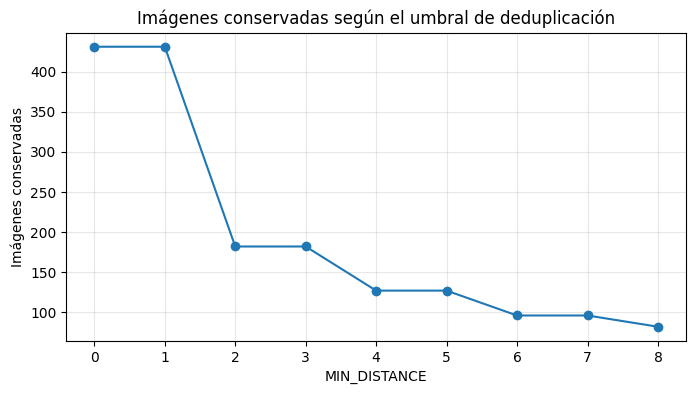

In [22]:
plt.figure(figsize=(8, 4))
plt.plot(sweep_df.index, sweep_df['kept_images'], marker='o')
plt.xlabel('MIN_DISTANCE')
plt.ylabel('Imágenes conservadas')
plt.title('Imágenes conservadas según el umbral de deduplicación')
plt.grid(alpha=0.3)
plt.show()

#### **Decisión: no deduplicar dentro de cada clase**

El barrido confirma que **ningún umbral de pHash es útil para este dataset**:

* **Incluso con `MIN_DISTANCE = 0` solo conservamos 431 imágenes (4,6%).** Con este valor únicamente descartamos imágenes cuyo pHash es *exactamente igual* al de otra ya conservada; es decir, cerca del 95% de las imágenes candidatas comparte el mismo hash con alguna otra. Como la cámara, el fondo y la forma de la fruta no cambian, el hash de 64 bits prácticamente no varía mientras la fruta se deteriora.
* **Los resultados aparecen en pares (0 = 1, 2 = 3, ...).** pHash compara cada coeficiente con la mediana, por lo que todos los hashes tienen casi la misma cantidad de unos y las distancias entre ellos son casi siempre pares.

Por eso **conservamos todas las imágenes que no están en conflicto**. Los duplicados no ponen en riesgo la evaluación porque FruQ-multi solo se usará para entrenar (ver 1.2.5); su único efecto es la redundancia, que controlaremos al combinarlo con otros datasets. pHash sí sigue siendo útil para lo que hicimos en 1.2.2 (detectar fronteras ambiguas entre clases) y para detectar copias de una misma imagen entre datasets distintos.

> Si en el futuro se necesita una deduplicación sensible al color, una alternativa es comparar embeddings de un modelo preentrenado (por ejemplo CLIP o DINOv2) con similitud coseno en lugar de pHash.

In [23]:
clean_df = candidates_df.reset_index(drop=True)

print(f"Imágenes originales: {len(images_df)}")
print(f"Imágenes conservadas: {len(clean_df)} ({len(clean_df) / len(images_df):.1%})")

Imágenes originales: 9370
Imágenes conservadas: 7996 (85.3%)


Eliminamos del disco las imágenes en conflicto para que la carpeta de FruQ-multi coincida con clean_df.

In [24]:
conflict_files = images_df.loc[images_df['is_conflict'], 'path']

for path in tqdm(conflict_files, desc='Eliminando conflictos'):
    Path(path).unlink(missing_ok=True)

remaining = sum(
    1 for path in DATASET_DIR.rglob('*')
    if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
)

print(f"Imágenes eliminadas: {len(conflict_files)}")
print(f"Imágenes restantes en disco: {remaining}")

Eliminando conflictos:   0%|          | 0/1374 [00:00<?, ?it/s]

Imágenes eliminadas: 1374
Imágenes restantes en disco: 7996


#### **1.2.4 Resultados de la limpieza**

Comparamos cuántas imágenes quedan por fruta y estado, después de normalizar las etiquetas y eliminar las fronteras ambiguas, frente a las originales.

In [25]:
before = images_df.groupby(['fruit', 'label']).size().unstack(fill_value=0)
after = clean_df.groupby(['fruit', 'label']).size().unstack(fill_value=0)

display(pd.concat({'before': before, 'after': after}, axis=1).fillna(0).astype(int))
display(clean_df['label'].value_counts())

before             after            
label        fresh mild rotten fresh mild rotten
fruit                                           
BananaDB       179   96    337    87   43    287
CucumberQ      250  345    116    70   94    116
GrapeQ         227  194    288   227  178    167
KakiQ          545  226    340   545  137    305
PapayaQ        130  250    413    30  172    413
PeachQ         425  136    584   425  136    584
PearQ          504  493    100   504  493    100
PepperQ         48   24    660    48   24    660
StrawberryQ      0  119     97     0  105     67
WatermeloQ      51   53    150    18   12    143
tomatoQ        600  440    950   584  308    914

,count
label,
rotten,3756
fresh,2538
mild,1702


Revisamos visualmente una muestra aleatoria de las imágenes conservadas de cada estado.

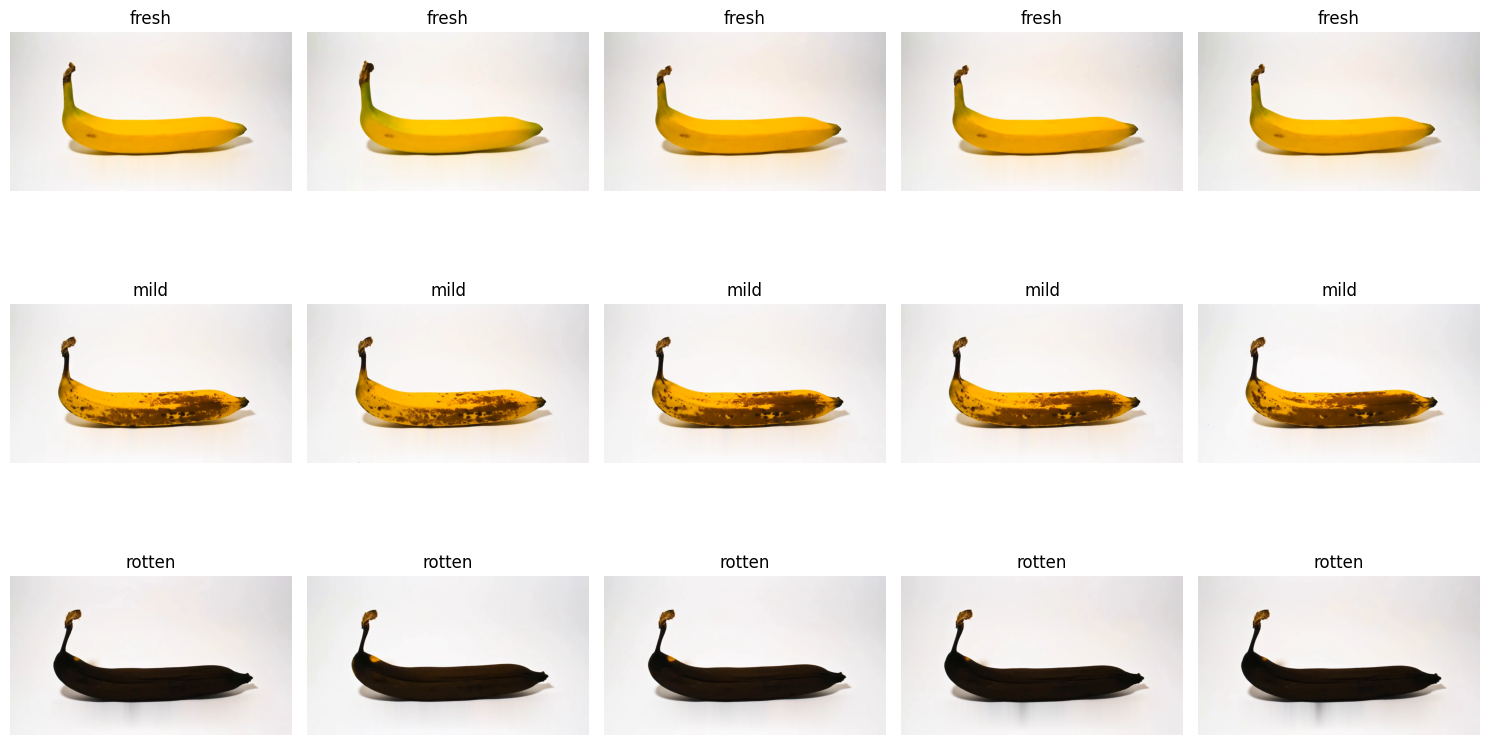

In [26]:
sample = (
    clean_df[clean_df['fruit'] == 'BananaDB']
    .groupby('label')
    .sample(5, random_state=42)
)

fig, axes = plt.subplots(sample['label'].nunique(), 5, figsize=(15, 9), squeeze=False)

for ax, (_, image) in zip(axes.ravel(), sample.iterrows()):
    ax.imshow(mpimg.imread(image['path']))
    ax.set_title(image['label'])
    ax.axis('off')

plt.tight_layout()
plt.show()

#### **1.2.5 Consideraciones para el entrenamiento**

FruQ-multi queda limpio de etiquetas inconsistentes y fronteras ambiguas, pero conserva sus casi-duplicados: todas las imágenes de una misma fruta vienen del mismo video, con el mismo fondo, la misma iluminación y la misma pieza de fruta. El experimento de deduplicación lo confirma: el dataset tiene apenas unas 82 vistas estructuralmente distintas. Por eso:

* **No usamos FruQ-multi como set de evaluación.** Si train y test salen del mismo video, el modelo puede aprender el fondo o la escena en lugar del estado de la fruta. El set de test debe venir de otras fuentes.
* **FruQ-multi es un complemento.** Las imágenes son de laboratorio, tienen poca diversidad y difieren de las fotos que tomarán los agricultores, así que necesitamos combinarlo con otros datasets públicos más variados.
* **Hay que revisar duplicados entre datasets.** Muchos datasets públicos de frutas se copian entre sí; si una misma imagen aparece en train y en test a través de dos fuentes distintas, las métricas se inflan. Para esto reutilizaremos `load_images` y `detect_duplicates` comparando imágenes entre fuentes.

## **2. FruitVision**

In [11]:
import shutil

DRIVE_DATASET_DIR = DRIVE_DIR / 'fruit_datasets' / 'Apple'

Ya sabemos que la estructura de FruQ-multi es `Fruta/Estado/imagen`.Procedemos a copiar las imágenes a FruQ-multi/Apple/<Estado> para poder reutilizar load_images y detect_duplicates sobre el dataset combinado.

In [28]:
target_root = DATASET_DIR / DRIVE_DATASET_DIR.name

for label in ['Fresh', 'Rotten']:
    source_dir = DRIVE_DATASET_DIR / label
    target_dir = target_root / label
    target_dir.mkdir(parents=True, exist_ok=True)

    # rglob porque dentro de cada estado hay subcarpetas (p. ej. Fresh/Fresh).
    paths = [
        path for path in sorted(source_dir.rglob('*'))
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
    ]

    for path in tqdm(paths, desc=f'Copiando {label}'):
        # Prefijamos con la subcarpeta para evitar nombres repetidos.
        name = '_'.join(path.relative_to(source_dir).parts)
        shutil.copy2(path, target_dir / name)

    print(f"{label}: {len(paths)} imágenes copiadas a {target_dir}")

Copiando Fresh:   0%|          | 0/6123 [00:00<?, ?it/s]

Fresh: 6123 imágenes copiadas a /content/drive/MyDrive/fruq/FruQ-multi/Apple/Fresh


Copiando Rotten:   0%|          | 0/377 [00:00<?, ?it/s]

Rotten: 377 imágenes copiadas a /content/drive/MyDrive/fruq/FruQ-multi/Apple/Rotten


## **3. Avocado Ripening Dataset**

Las imágenes de este dataset no están separadas en carpetas: su etiqueta está en el `.xlsx` (columna `Ripening Index Classification`, de 1 a 5). Mapeamos las clases a los estados de Agrotrace: 2 y 3 → `fresh`, 4 → `mild` y 5 → `rotten`. La clase 1 (aguacate inmaduro) no corresponde a ninguno de nuestros estados, así que la descartamos.

In [29]:
AVOCADO_DIR = DRIVE_DIR / 'fruit_datasets' / 'Avocado_Ripening_Dataset'
AVOCADO_LABELS_PATH = AVOCADO_DIR / 'Avocado Ripening Dataset.xlsx'

In [30]:
AVOCADO_LABEL_MAPPING = {
    2: 'Fresh',
    3: 'Fresh',
    4: 'Mild',
    5: 'Rotten',
}

labels_df = pd.read_excel(AVOCADO_LABELS_PATH)
labels_df.columns = labels_df.columns.str.strip()
labels_df['label'] = labels_df['Ripening Index Classification'].map(AVOCADO_LABEL_MAPPING)

display(labels_df['Ripening Index Classification'].value_counts().sort_index())

,count
Ripening Index Classification,
1,3572
2,2234
3,2758
4,3294
5,2864


Procedemos a copiar las imagenes bajo el orden que ya definimos, en este caso el .xlsx guarda el nombre sin extensión, así que buscamos cada imagen por su nombre base.

In [31]:
avocado_paths = {
    path.stem: path for path in AVOCADO_DIR.iterdir()
    if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
}


target_root = DATASET_DIR / 'Avocado'
copied = defaultdict(int)
missing = []

for _, row in tqdm(labels_df.dropna(subset=['label']).iterrows(), desc='Copiando aguacates'):
    path = avocado_paths.get(str(row['File Name']).strip())

    if path is None:
        missing.append(row['File Name'])
        continue

    target_dir = target_root / row['label']
    target_dir.mkdir(parents=True, exist_ok=True)
    shutil.copy2(path, target_dir / path.name)
    copied[row['label']] += 1

print(f"Imágenes copiadas por estado: {dict(copied)}")
print(f"Descartadas (clase 1): {(labels_df['Ripening Index Classification'] == 1).sum()}")
print(f"Etiquetas sin imagen en la carpeta: {len(missing)}")

Copiando aguacates: 0it [00:00, ?it/s]

Imágenes copiadas por estado: {'Fresh': 4984, 'Mild': 3294, 'Rotten': 2864}
Descartadas (clase 1): 3572
Etiquetas sin imagen en la carpeta: 8


Pasemos las imagenes desde la carpeta `Good` a `Fresh` ya que esta última es la etiqueta final que usaremos para el dataset que subiremos a Hugging Face.

In [32]:
!mv "{DATASET_DIR}"/Avocado/Good/* "{DATASET_DIR}"/Avocado/Fresh/

mv: cannot stat '/content/drive/MyDrive/fruq/FruQ-multi/Avocado/Good/*': No such file or directory


In [33]:
!rm -rf "{DATASET_DIR}"/Avocado/Good

## **4. AgriFresh NET**



In [3]:
import re

AGRIFRESH_DIR = DRIVE_DIR / 'fruit_datasets' / 'AgriFresh_Net'

# Fruta de AgriFresh → carpeta de la misma fruta en FruQ-multi.
AGRIFRESH_FRUITS = {
    'banana': 'BananaDB',
    'cucumber': 'CucumberQ',
    'papaya': 'PapayaQ',
    'tomato': 'tomatoQ',
}

# Estado de AgriFresh → estado de Agrotrace.
AGRIFRESH_LABELS = {
    'fresh': 'fresh',
    'semi fresh': 'mild',
    'rotten': 'rotten',
}

Las subcarpetas de AgriFresh siguen el formato `<Estado> <Fruta>(<rango>)`, por ejemplo `Fresh Banana(1-4)` o `Semi fresh banana(4-7)`, con mayúsculas inconsistentes. Leemos el estado y la fruta del nombre y copiamos cada imagen a la carpeta del mismo estado en FruQ-multi. Como los nombres de archivo son genéricos (`IMG_...jpg`), les agregamos el prefijo `agrifresh_` para evitar choques y saber de qué fuente viene cada imagen.

In [12]:
FOLDER_PATTERN = re.compile(r'^(fresh|semi fresh|rotten)\s+([a-z]+)', re.IGNORECASE)

# Las carpetas de estado de FruQ-multi no usan los mismos nombres en todas las frutas.
STATE_ALIASES = {
    'fresh': {'good', 'fresh'},
    'mild': {'mild'},
    'rotten': {'rotten'},
}


def find_state_dir(fruit_dir: Path, label: str) -> Path:
    """Devuelve la carpeta de `label` dentro de `fruit_dir`, sin importar cómo esté escrita."""
    for state_dir in fruit_dir.iterdir():
        if state_dir.is_dir() and state_dir.name.lower() in STATE_ALIASES[label]:
            return state_dir

    state_dir = fruit_dir / label.capitalize()
    state_dir.mkdir(parents=True, exist_ok=True)
    return state_dir


copied = []

for source_dir in sorted(AGRIFRESH_DIR.iterdir()):
    match = FOLDER_PATTERN.match(source_dir.name) if source_dir.is_dir() else None

    if match is None or match.group(2).lower() not in AGRIFRESH_FRUITS:
        print(f'Se omite: {source_dir.name}')
        continue

    state, fruit = match.group(1).lower(), match.group(2).lower()
    label = AGRIFRESH_LABELS[' '.join(state.split())]
    target_dir = find_state_dir(DATASET_DIR / AGRIFRESH_FRUITS[fruit], label)

    paths = [
        path for path in sorted(source_dir.rglob('*'))
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
    ]

    for path in tqdm(paths, desc=source_dir.name):
        shutil.copy2(path, target_dir / f'agrifresh_{path.name}')

    copied.append({
        'source': source_dir.name,
        'target': str(target_dir.relative_to(DATASET_DIR)),
        'images': len(paths),
    })

display(pd.DataFrame(copied))

Fresh Banana(1-4):   0%|          | 0/590 [00:00<?, ?it/s]

Fresh Cucumber(1-6):   0%|          | 0/590 [00:00<?, ?it/s]

Fresh Papaya(1-4):   0%|          | 0/590 [00:00<?, ?it/s]

Fresh Tomato(1-10):   0%|          | 0/590 [00:00<?, ?it/s]

Rotten Cucumber(12-20):   0%|          | 0/590 [00:00<?, ?it/s]

...

Semi Fresh Cucumber(6-12):   0%|          | 0/590 [00:00<?, ?it/s]

Semi Fresh Papaya(4-7):   0%|          | 0/590 [00:00<?, ?it/s]

Semi fresh Tomato(10-24):   0%|          | 0/590 [00:00<?, ?it/s]

Semi fresh banana(4-7):   0%|          | 0/590 [00:00<?, ?it/s]

,source,target,images
0,Fresh Banana(1-4),BananaDB/Good,590
1,Fresh Cucumber(1-6),CucumberQ/Fresh,590
2,Fresh Papaya(1-4),PapayaQ/Good,590
3,Fresh Tomato(1-10),tomatoQ/Good,590
4,Rotten Cucumber(12-20),CucumberQ/Rotten,590
5,Rotten Papaya(7-12),PapayaQ/Rotten,590
6,Rotten Tomato(24-35),tomatoQ/Rotten,590
7,Rotten banana(7-13),BananaDB/Rotten,590
8,Semi Fresh Cucumber(6-12),CucumberQ/Mild,590
9,Semi Fresh Papaya(4-7),PapayaQ/Mild,590


Por último, renombramos las carpetas `Good` a `Fresh` en todas las frutas de FruQ-multi, ya que `Fresh` es la etiqueta final del dataset. Si una fruta ya tiene ambas carpetas, movemos las imágenes de `Good` a `Fresh` y eliminamos `Good`.

In [13]:
for fruit_dir in sorted(DATASET_DIR.iterdir()):
    good_dir = fruit_dir / 'Good'

    if not good_dir.is_dir():
        continue

    fresh_dir = fruit_dir / 'Fresh'

    if fresh_dir.exists():
        for path in good_dir.iterdir():
            shutil.move(str(path), fresh_dir / path.name)
        good_dir.rmdir()
    else:
        good_dir.rename(fresh_dir)

    print(f'{fruit_dir.name}: Good → Fresh')

!ls "{DATASET_DIR}"/*

BananaDB: Good → Fresh
GrapeQ: Good → Fresh
KakiQ: Good → Fresh
PapayaQ: Good → Fresh
PeachQ: Good → Fresh
PearQ: Good → Fresh
PepperQ: Good → Fresh
WatermeloQ: Good → Fresh
tomatoQ: Good → Fresh
/content/drive/MyDrive/fruq/FruQ-multi/Apple:
Fresh  Rotten

/content/drive/MyDrive/fruq/FruQ-multi/Avocado:
Fresh  Mild  Rotten

/content/drive/MyDrive/fruq/FruQ-multi/BananaDB:
Fresh  mild  Rotten

/content/drive/MyDrive/fruq/FruQ-multi/CucumberQ:
Fresh  Mild  Rotten

/content/drive/MyDrive/fruq/FruQ-multi/GrapeQ:
Fresh  Mild  Rotten

/content/drive/MyDrive/fruq/FruQ-multi/KakiQ:
Fresh  Mild  Rotten

/content/drive/MyDrive/fruq/FruQ-multi/PapayaQ:
Fresh  Mild  Rotten

/content/drive/MyDrive/fruq/FruQ-multi/PeachQ:
Fresh  Mild  Rotten

/content/drive/MyDrive/fruq/FruQ-multi/PearQ:
Fresh  Mild  Rotten

/content/drive/MyDrive/fruq/FruQ-multi/PepperQ:
Fresh  Mild  Rotten

/content/drive/MyDrive/fruq/FruQ-multi/StrawberryQ:
Mild  Rotten

/content/drive/MyDrive/fruq/FruQ-multi/tomatoQ:
Fresh  Mild

## **5. Procesamiento y creación del dataset final**

Ya tenemos las imagenes que conformarán nuestro dataset final que será subido a Hugging face, para este caso en especifico vamos a guardar dos carpetas:

- `original:` Aquí subiremos las imagenes originales del dataset con subcarpetas de `Fresh`, `Mild` y `Rotten`.
- `crop:` Utilizaremos el modelo de detección (Yolo 26 s) para detectar las frutas en las imagenes y haremos un recorte basandones en el bounding box para quedarnos solo con la imagen de la fruta descartando su fondo.